# Mercari Price Suggestion Challenge — Baseline

Memprediksi harga jual barang di marketplace Mercari dari judul, deskripsi, kategori, brand, kondisi, dan status ongkir.

- **Metrik:** RMSLE. Target di-`log1p`, lalu cukup dilatih dengan loss MSE biasa.
- **Pendekatan:** TF-IDF / CountVectorizer + fitur kategorikal → Ridge Regression.
- **Memori:** run penuh (1,48 juta baris) butuh sekitar 8 GB RAM atau lebih. Kalau RAM kecil, isi `SAMPLE` di sel konfigurasi.

**Isi notebook**
1. Konfigurasi dan impor
2. Memuat data
3. Eksplorasi singkat
4. Preprocessing
5. Rekayasa fitur
6. Validasi lokal
7. Latih ulang di seluruh data dan buat `submission.csv`

## 1. Konfigurasi dan impor

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

# ---------- KONFIGURASI ----------
# Folder data. Otomatis memakai folder Kaggle kalau ada, selain itu folder kerja saat ini.
KAGGLE_DIR = "/kaggle/input/mercari-price-suggestion-challenge"
DATA_DIR = KAGGLE_DIR if os.path.isdir(KAGGLE_DIR) else "."

TRAIN_FILE = "train.tsv"
TEST_FILE = "test.tsv"          # stage 1 (~693 ribu baris); stage 2: "test_stg2.tsv"
SUBMISSION_FILE = "submission.csv"

# None = pakai seluruh data. Isi angka (mis. 200_000) untuk uji cepat / RAM kecil.
SAMPLE = None

RANDOM_STATE = 42
VAL_SIZE = 0.1
RIDGE_ALPHA = 3.0

## 2. Memuat data

File dari Kaggle berformat `.7z`. Kalau `train.tsv` belum ada di folder data, sel di bawah mencoba mengekstraknya
dengan `py7zr` (`pip install py7zr`). Kalau kamu sudah mengekstraknya sendiri, sel ini langsung dilewati.

In [2]:
def ensure_extracted(tsv_name, archive_name):
    tsv_path = os.path.join(DATA_DIR, tsv_name)
    if os.path.exists(tsv_path):
        return tsv_path
    archive_path = os.path.join(DATA_DIR, archive_name)
    if not os.path.exists(archive_path):
        raise FileNotFoundError(f"Tidak menemukan {tsv_path} maupun {archive_path}")
    import py7zr  # pip install py7zr
    with py7zr.SevenZipFile(archive_path, "r") as z:
        z.extractall(DATA_DIR)
    return tsv_path

train_path = ensure_extracted(TRAIN_FILE, "train_tsv.7z")
test_path = ensure_extracted(TEST_FILE, "test_tsv.7z")

train = pd.read_csv(train_path, sep="\t")
test = pd.read_csv(test_path, sep="\t")

if SAMPLE:
    train = train.sample(SAMPLE, random_state=RANDOM_STATE).reset_index(drop=True)
    test = test.head(max(SAMPLE // 4, 1000)).reset_index(drop=True)

print("train:", train.shape, "| test:", test.shape)
train.head()

train: (1482535, 8) | test: (693359, 7)


,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
0,0,MLB Cincinnati Reds T Shirt Size XL,3,Men/Tops/T-shirts,NaN,10.0,1,No description yet
1,1,Razer BlackWidow Chroma Keyboard,3,Electronics/Computers & Tablets/Components & P...,Razer,52.0,0,This keyboard is in great condition and works ...
2,2,AVA-VIV Blouse,1,Women/Tops & Blouses/Blouse,Target,10.0,1,Adorable top with a hint of lace and a key hol...
3,3,Leather Horse Statues,1,Home/Home Décor/Home Décor Accents,NaN,35.0,1,New with tags. Leather horses. Retail for [rm]...
4,4,24K GOLD plated rose,1,Women/Jewelry/Necklaces,NaN,44.0,0,Complete with certificate of authenticity


## 3. Eksplorasi singkat

In [3]:
print("Nilai kosong (train):")
print(train.isna().sum()[lambda s: s > 0])
print()
print("Harga <= 0:", (train["price"] <= 0).sum(), "baris (akan dibuang)")
print()
print(train["price"].describe())

Nilai kosong (train):
category_name         6327
brand_name          632682
item_description         6
dtype: int64

Harga <= 0: 874 baris (akan dibuang)

count    1.482535e+06
mean     2.673752e+01
std      3.858607e+01
min      0.000000e+00
25%      1.000000e+01
50%      1.700000e+01
75%      2.900000e+01
max      2.009000e+03
Name: price, dtype: float64


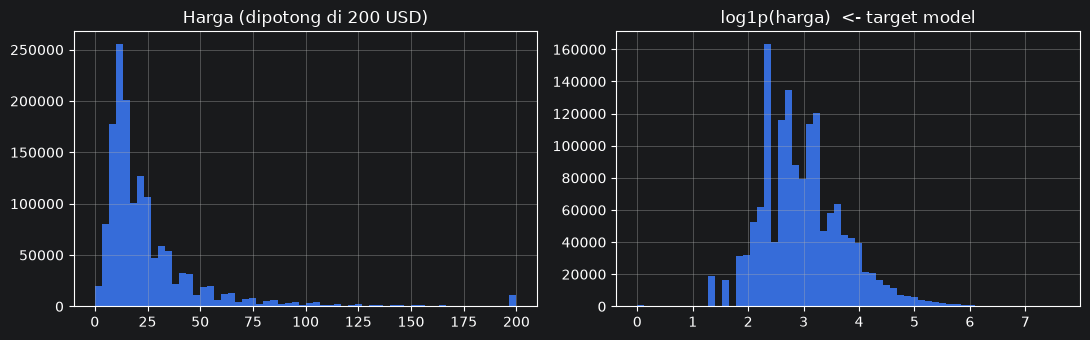

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
train["price"].clip(upper=200).hist(bins=60, ax=axes[0])
axes[0].set_title("Harga (dipotong di 200 USD)")
np.log1p(train["price"]).hist(bins=60, ax=axes[1])
axes[1].set_title("log1p(harga)  <- target model")
plt.tight_layout()
plt.show()

In [5]:
print(train["item_condition_id"].value_counts().sort_index().to_string())
print()
print("Rata-rata harga menurut shipping:")
print(train.groupby("shipping")["price"].mean().round(2).to_string())
print()
print("10 brand terbanyak:")
print(train["brand_name"].value_counts().head(10).to_string())

item_condition_id
1    640549
2    375479
3    432161
4     31962
5      2384

Rata-rata harga menurut shipping:
shipping
0    30.11
1    22.57

10 brand terbanyak:
brand_name
PINK                 54088
Nike                 54043
Victoria's Secret    48036
LuLaRoe              31024
Apple                17322
FOREVER 21           15186
Nintendo             15007
Lululemon            14558
Michael Kors         13928
American Eagle       13254


## 4. Preprocessing

- Buang baris dengan `price <= 0`.
- Isi nilai kosong.
- Pecah `category_name` (mis. `Women/Tops & Blouses/Blouse`) menjadi 3 level.

In [6]:
def preprocess(df):
    df = df.copy()
    df["category_name"] = df["category_name"].fillna("missing/missing/missing")
    df["brand_name"] = df["brand_name"].fillna("missing")
    df["item_description"] = df["item_description"].fillna("missing")
    df["name"] = df["name"].fillna("missing")

    cats = df["category_name"].str.split("/", n=2, expand=True)
    df["cat1"] = cats[0].fillna("missing")
    df["cat2"] = cats[1].fillna("missing")
    df["cat3"] = cats[2].fillna("missing")
    return df

train = train[train["price"] > 0].reset_index(drop=True)
y = np.log1p(train["price"].values)

train = preprocess(train)
test = preprocess(test)
print("train setelah dibersihkan:", train.shape)

train setelah dibersihkan: (1481661, 11)


## 5. Rekayasa fitur

Semua fitur berbentuk sparse matrix supaya hemat memori. Setiap vectorizer di-*fit* hanya pada data latih,
lalu dipakai untuk men-*transform* data validasi atau test.

In [7]:
def build_features(train_df, test_df):
    """Fit vectorizer di train_df, transform keduanya. Return (X_train, X_test) sparse CSR."""
    parts_train, parts_test = [], []

    def add(vec, col):
        parts_train.append(vec.fit_transform(train_df[col]))
        parts_test.append(vec.transform(test_df[col]))

    add(CountVectorizer(min_df=2, ngram_range=(1, 2), max_features=100_000), "name")
    add(TfidfVectorizer(ngram_range=(1, 2), max_features=200_000, stop_words="english",
                        min_df=2, sublinear_tf=True), "item_description")
    add(LabelBinarizer(sparse_output=True), "brand_name")
    for col in ["cat1", "cat2", "cat3"]:
        add(CountVectorizer(token_pattern=".+"), col)

    # item_condition_id (1-5) dan shipping (0/1) sebagai one-hot
    cond_train = pd.get_dummies(train_df[["item_condition_id", "shipping"]].astype("category"), sparse=True)
    cond_test = pd.get_dummies(test_df[["item_condition_id", "shipping"]].astype("category"), sparse=True)
    cond_test = cond_test.reindex(columns=cond_train.columns, fill_value=0)
    parts_train.append(cond_train.sparse.to_coo().tocsr())
    parts_test.append(cond_test.sparse.to_coo().tocsr())

    return hstack(parts_train).tocsr(), hstack(parts_test).tocsr()


def rmsle(y_true_log, y_pred_log):
    """Target sudah di-log1p, jadi RMSLE = RMSE di ruang log."""
    return np.sqrt(np.mean((y_true_log - y_pred_log) ** 2))

## 6. Validasi lokal (hold-out 10%)

In [8]:
t0 = time.time()
tr_idx, va_idx = train_test_split(np.arange(len(train)), test_size=VAL_SIZE, random_state=RANDOM_STATE)

X_tr, X_va = build_features(train.iloc[tr_idx], train.iloc[va_idx])
print("Bentuk fitur:", X_tr.shape)

model = Ridge(alpha=RIDGE_ALPHA, solver="auto", random_state=RANDOM_STATE)
model.fit(X_tr, y[tr_idx])

val_pred = model.predict(X_va)
print(f"Validation RMSLE: {rmsle(y[va_idx], val_pred):.5f}   ({time.time() - t0:.0f} detik)")

Bentuk fitur: (1333494, 305675)
Validation RMSLE: 0.43932   (495 detik)


In [9]:
# Coba beberapa nilai alpha pada fitur yang sama (opsional, cepat)
for a in [1.0, 3.0, 5.0, 10.0]:
    m = Ridge(alpha=a, solver="auto", random_state=RANDOM_STATE).fit(X_tr, y[tr_idx])
    print(f"alpha={a:<5} RMSLE={rmsle(y[va_idx], m.predict(X_va)):.5f}")

alpha=1.0   RMSLE=0.44621
alpha=3.0   RMSLE=0.43932
alpha=5.0   RMSLE=0.43800
alpha=10.0  RMSLE=0.43870


In [10]:
# Bebaskan memori sebelum latih ulang di seluruh data
del X_tr, X_va, model
import gc; gc.collect()

436

## 7. Latih ulang di seluruh data dan buat submission

In [11]:
t0 = time.time()
X_full, X_test = build_features(train, test)
model = Ridge(alpha=RIDGE_ALPHA, solver="auto", random_state=RANDOM_STATE)
model.fit(X_full, y)

pred = np.expm1(model.predict(X_test)).clip(min=3)   # harga minimum di data = 3 USD

submission = pd.DataFrame({"test_id": test["test_id"], "price": pred})
submission.to_csv(SUBMISSION_FILE, index=False)
print(f"Tersimpan: {SUBMISSION_FILE}  {submission.shape}  ({time.time() - t0:.0f} detik)")
submission.head()

Tersimpan: submission.csv  (693359, 2)  (769 detik)


,test_id,price
0,0,8.989138
1,1,8.039340
2,2,66.619468
3,3,13.273362
4,4,7.974993


## Langkah berikutnya

1. Tuning `RIDGE_ALPHA` dan ukuran TF-IDF (`max_features`, `ngram_range`).
2. Tambah fitur buatan: panjang deskripsi, ada tidaknya brand, flag `No description yet`.
3. Ensemble dengan LightGBM pada fitur sparse yang sama.
4. Coba MLP sparse; solusi juara banyak memakainya, lalu rata-ratakan dengan Ridge.